# TASK 3: Data Analysis & Visualization

This notebook performs the data-processing calculations directly, reports the warm-up filtering and latency quantiles, and generates the two publication-ready figures.

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT / "src"))
np.random.seed(42)
print(f"Project root: {PROJECT_ROOT}")
print("Random seed fixed to 42.")


Project root: C:\narxoz\методы исслед\Evaluating-the-Effectiveness-of-AI-Text-Detectors-in-Academic-Writing
Random seed fixed to 42.


## 1. Load logs and remove warm-up runs

Warm-up (cold-start) repetitions are excluded before any latency statistic is calculated. The cell below shows the exact counts retained and discarded, so the filtering step is auditable.

In [2]:
from process_data import (
    load_jsonl,
    split_warmup,
    latency_summary,
    load_scored,
    quality_table,
    metrics_summary,
)

runs = load_jsonl(PROJECT_ROOT / "data/raw/test_run.jsonl")
eval_runs, warmup_runs = split_warmup(runs)
print(f"Warm-up latency runs discarded: {len(warmup_runs)}")
print(f"Evaluation latency runs retained: {len(eval_runs)}")

latency = latency_summary(eval_runs, seed=42)
scored, thresholds = load_scored(PROJECT_ROOT / "data/raw")
quality = quality_table(scored, n_boot=2000, seed=42)
metrics = metrics_summary(quality, latency)

print("Frozen validation thresholds:")
display(pd.Series(thresholds, name="threshold"))
print("Quality metrics and guardrails:")
display(metrics[["detector", "f1", "f1_ci95_lo", "f1_ci95_hi", "auroc", "fnr", "fpr_human", "guard_fpr_le_5pct"]].round(3))


Warm-up latency runs discarded: 60
Evaluation latency runs retained: 600


Frozen validation thresholds:


ensemble_mean            0.370676
lexical_formality        0.512803
random_baseline          0.913511
stylometric_heuristic    0.272473
Name: threshold, dtype: float64

Quality metrics and guardrails:


,detector,f1,f1_ci95_lo,f1_ci95_hi,auroc,fnr,fpr_human,guard_fpr_le_5pct
0,ensemble_mean,0.917,0.888,0.945,0.969,0.090,0.100,False
1,lexical_formality,0.795,0.746,0.842,0.889,0.280,0.121,False
2,random_baseline,0.157,0.093,0.222,0.489,0.910,0.079,False
3,stylometric_heuristic,0.924,0.893,0.950,0.979,0.095,0.071,False


## 2. Latency distribution

Latency is summarized after warm-up removal. The median and interquartile range describe the typical run, while p95 and p99 make the tail behavior explicit at the reference batch size of 16 documents.

In [3]:
latency_at_reference_load = latency[latency["batch_size"] == 16].copy()
latency_view = latency_at_reference_load[[
    "detector", "n_runs", "median_ms", "p25_ms", "p75_ms", "p95_ms", "p99_ms",
    "ci95_lo_ms", "ci95_hi_ms", "median_ms_per_doc", "p99_ms_per_doc",
]]
display(latency_view.round(3))
latency.to_csv(PROJECT_ROOT / "data/processed/latency_summary.csv", index=False)
metrics.to_csv(PROJECT_ROOT / "data/processed/metrics_summary.csv", index=False)


,detector,n_runs,median_ms,p25_ms,p75_ms,p95_ms,p99_ms,ci95_lo_ms,ci95_hi_ms,median_ms_per_doc,p99_ms_per_doc
2,ensemble_mean,30,4.994,4.910,5.199,6.286,7.151,4.933,5.105,0.312,0.447
7,lexical_formality,30,2.764,2.653,3.078,4.595,5.539,2.705,2.935,0.173,0.346
12,random_baseline,30,0.010,0.010,0.011,0.015,0.018,0.010,0.010,0.001,0.001
17,stylometric_heuristic,30,2.238,2.206,2.316,2.461,3.349,2.216,2.269,0.140,0.209


## 3. Scientific visualization

The plots use the same calculated tables as the report. The random baseline remains in the tabular results as a chance reference, but is omitted from the figures to keep the detector comparison readable.

In [4]:
import visualize

visualize.FIG_DIR = PROJECT_ROOT / "reports/figures"
visualize.FIG_DIR.mkdir(parents=True, exist_ok=True)
plot_metrics = metrics[metrics["detector"] != "random_baseline"]
plot_latency = latency[latency["detector"] != "random_baseline"]
visualize.plot_latency_vs_load(plot_latency)
visualize.plot_f1_distribution(plot_metrics)
print(f"Figures saved in {visualize.FIG_DIR}")


C:\narxoz\методы исслед\Evaluating-the-Effectiveness-of-AI-Text-Detectors-in-Academic-Writing\src\visualize.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=df, x="detector", y="f1", palette="colorblind", capsize=.1, errorbar=None)


Figures saved in C:\narxoz\методы исслед\Evaluating-the-Effectiveness-of-AI-Text-Detectors-in-Academic-Writing\reports\figures


Figure 1: Latency vs Load


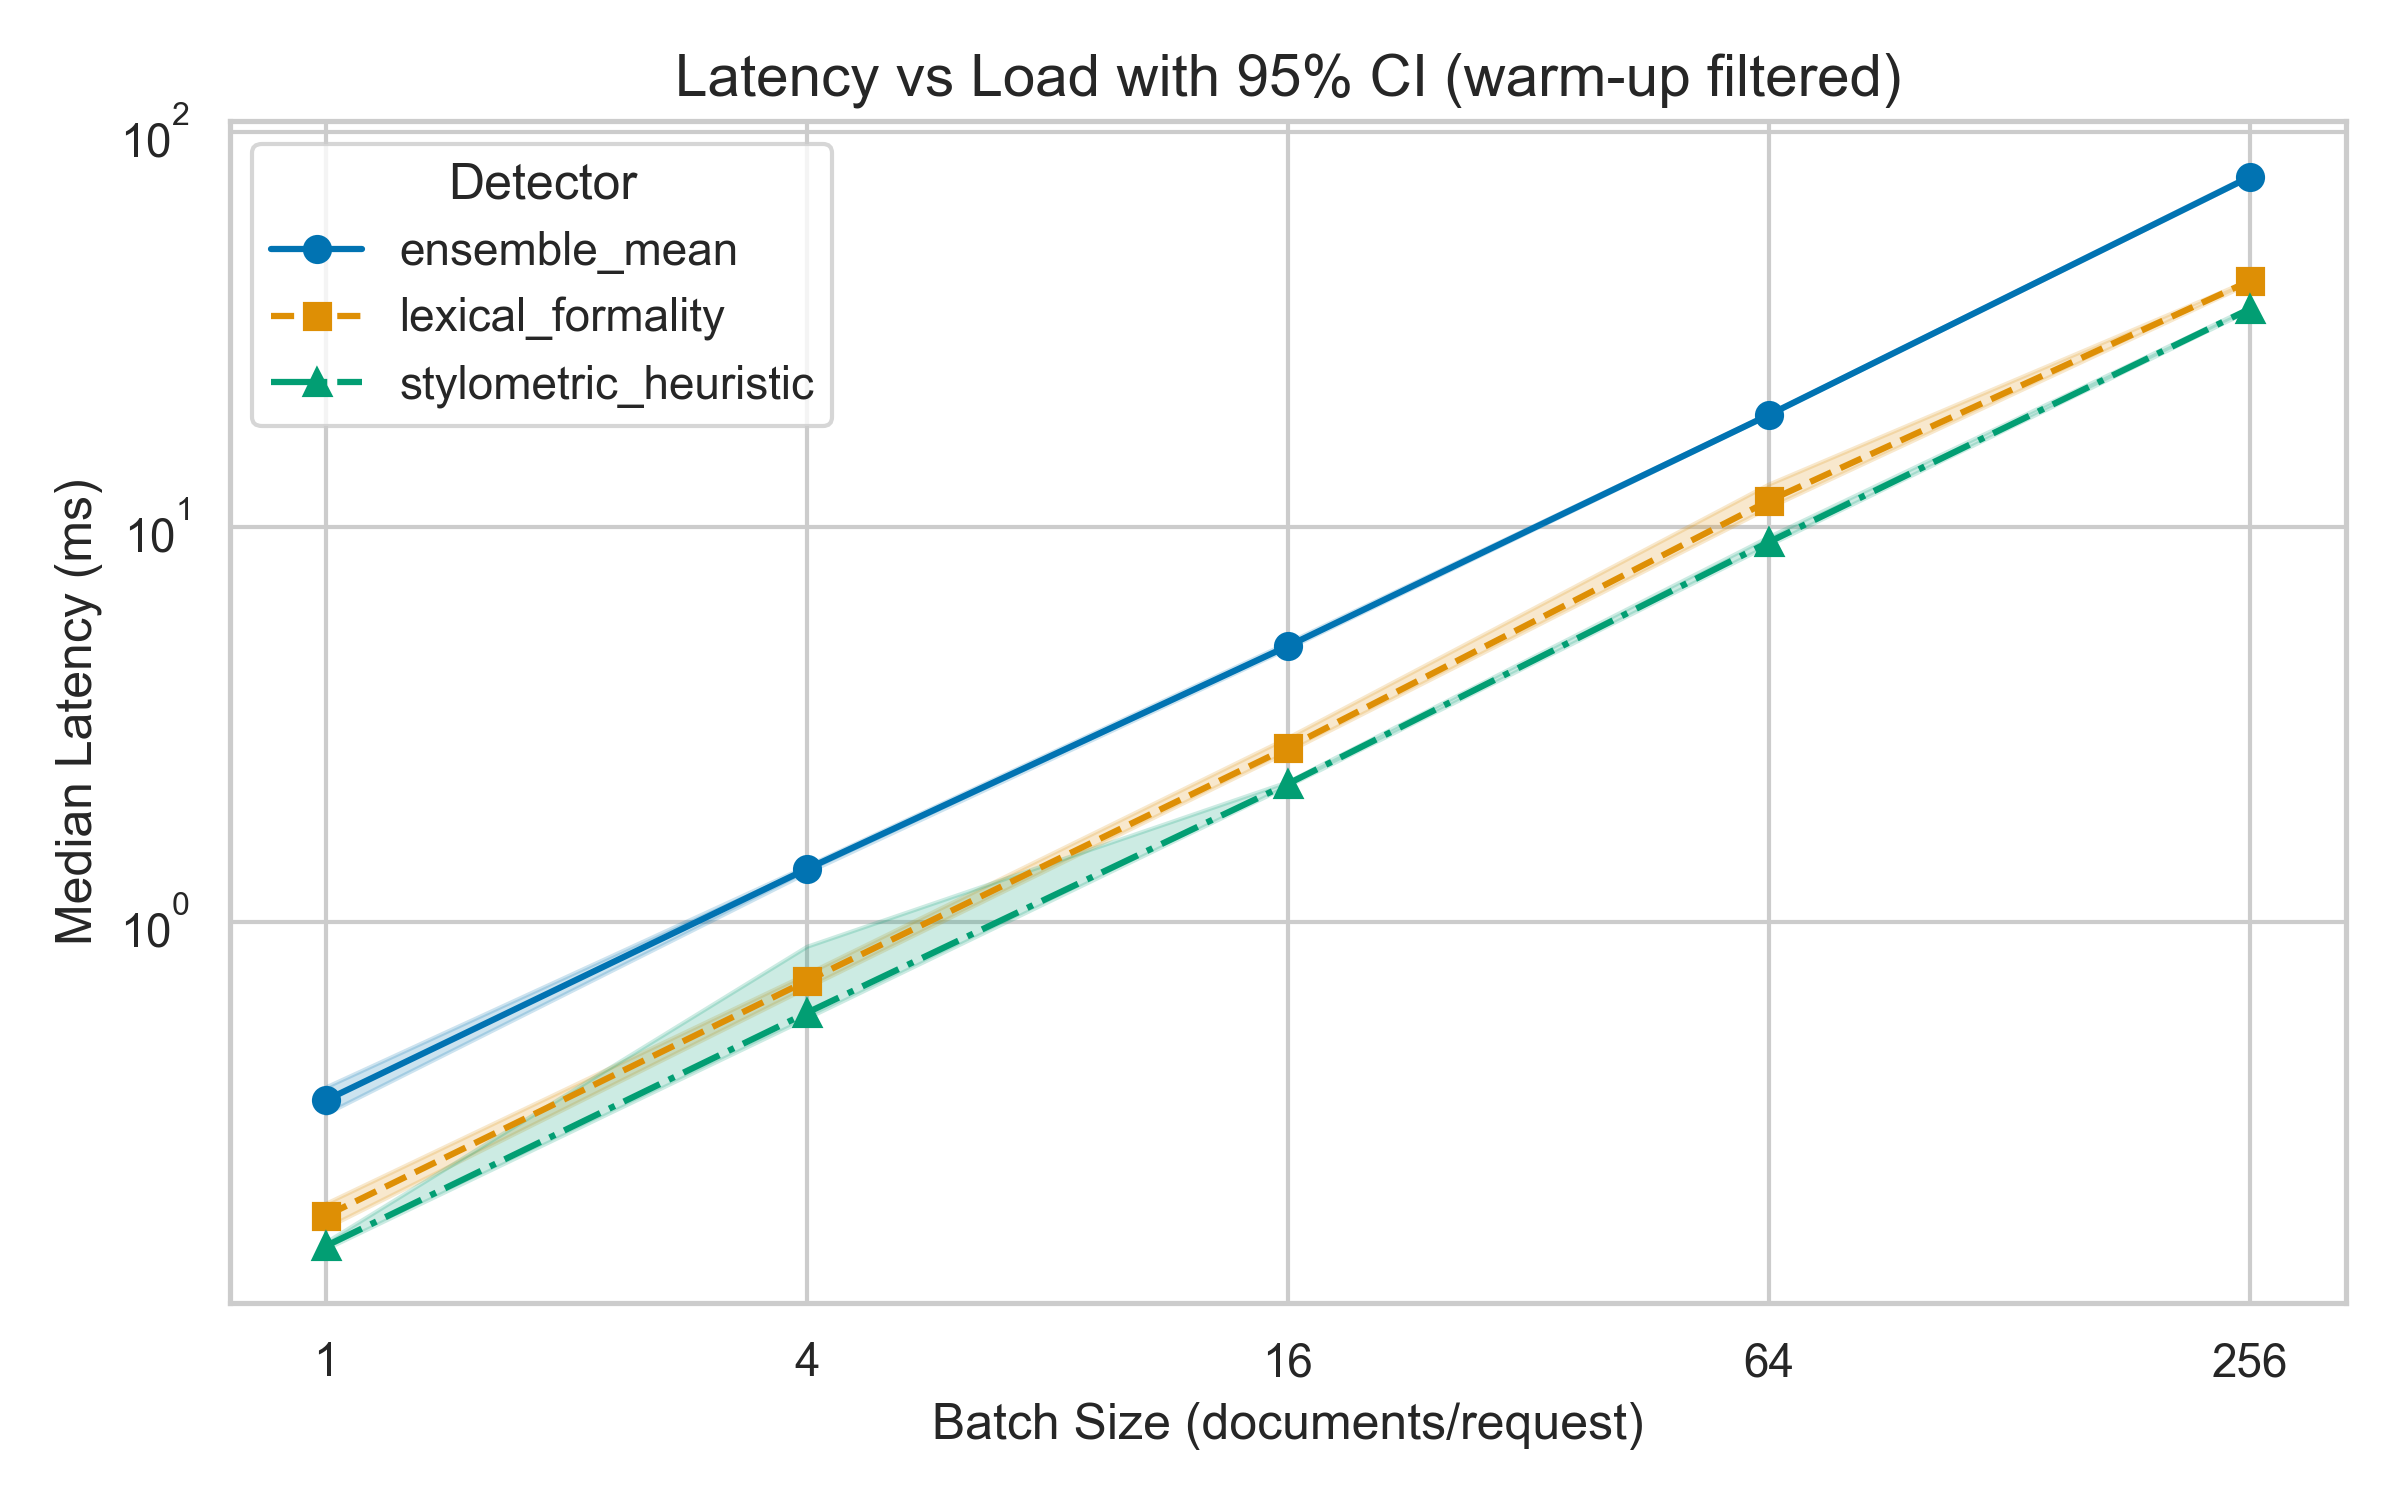

Figure 2: F1 Distribution


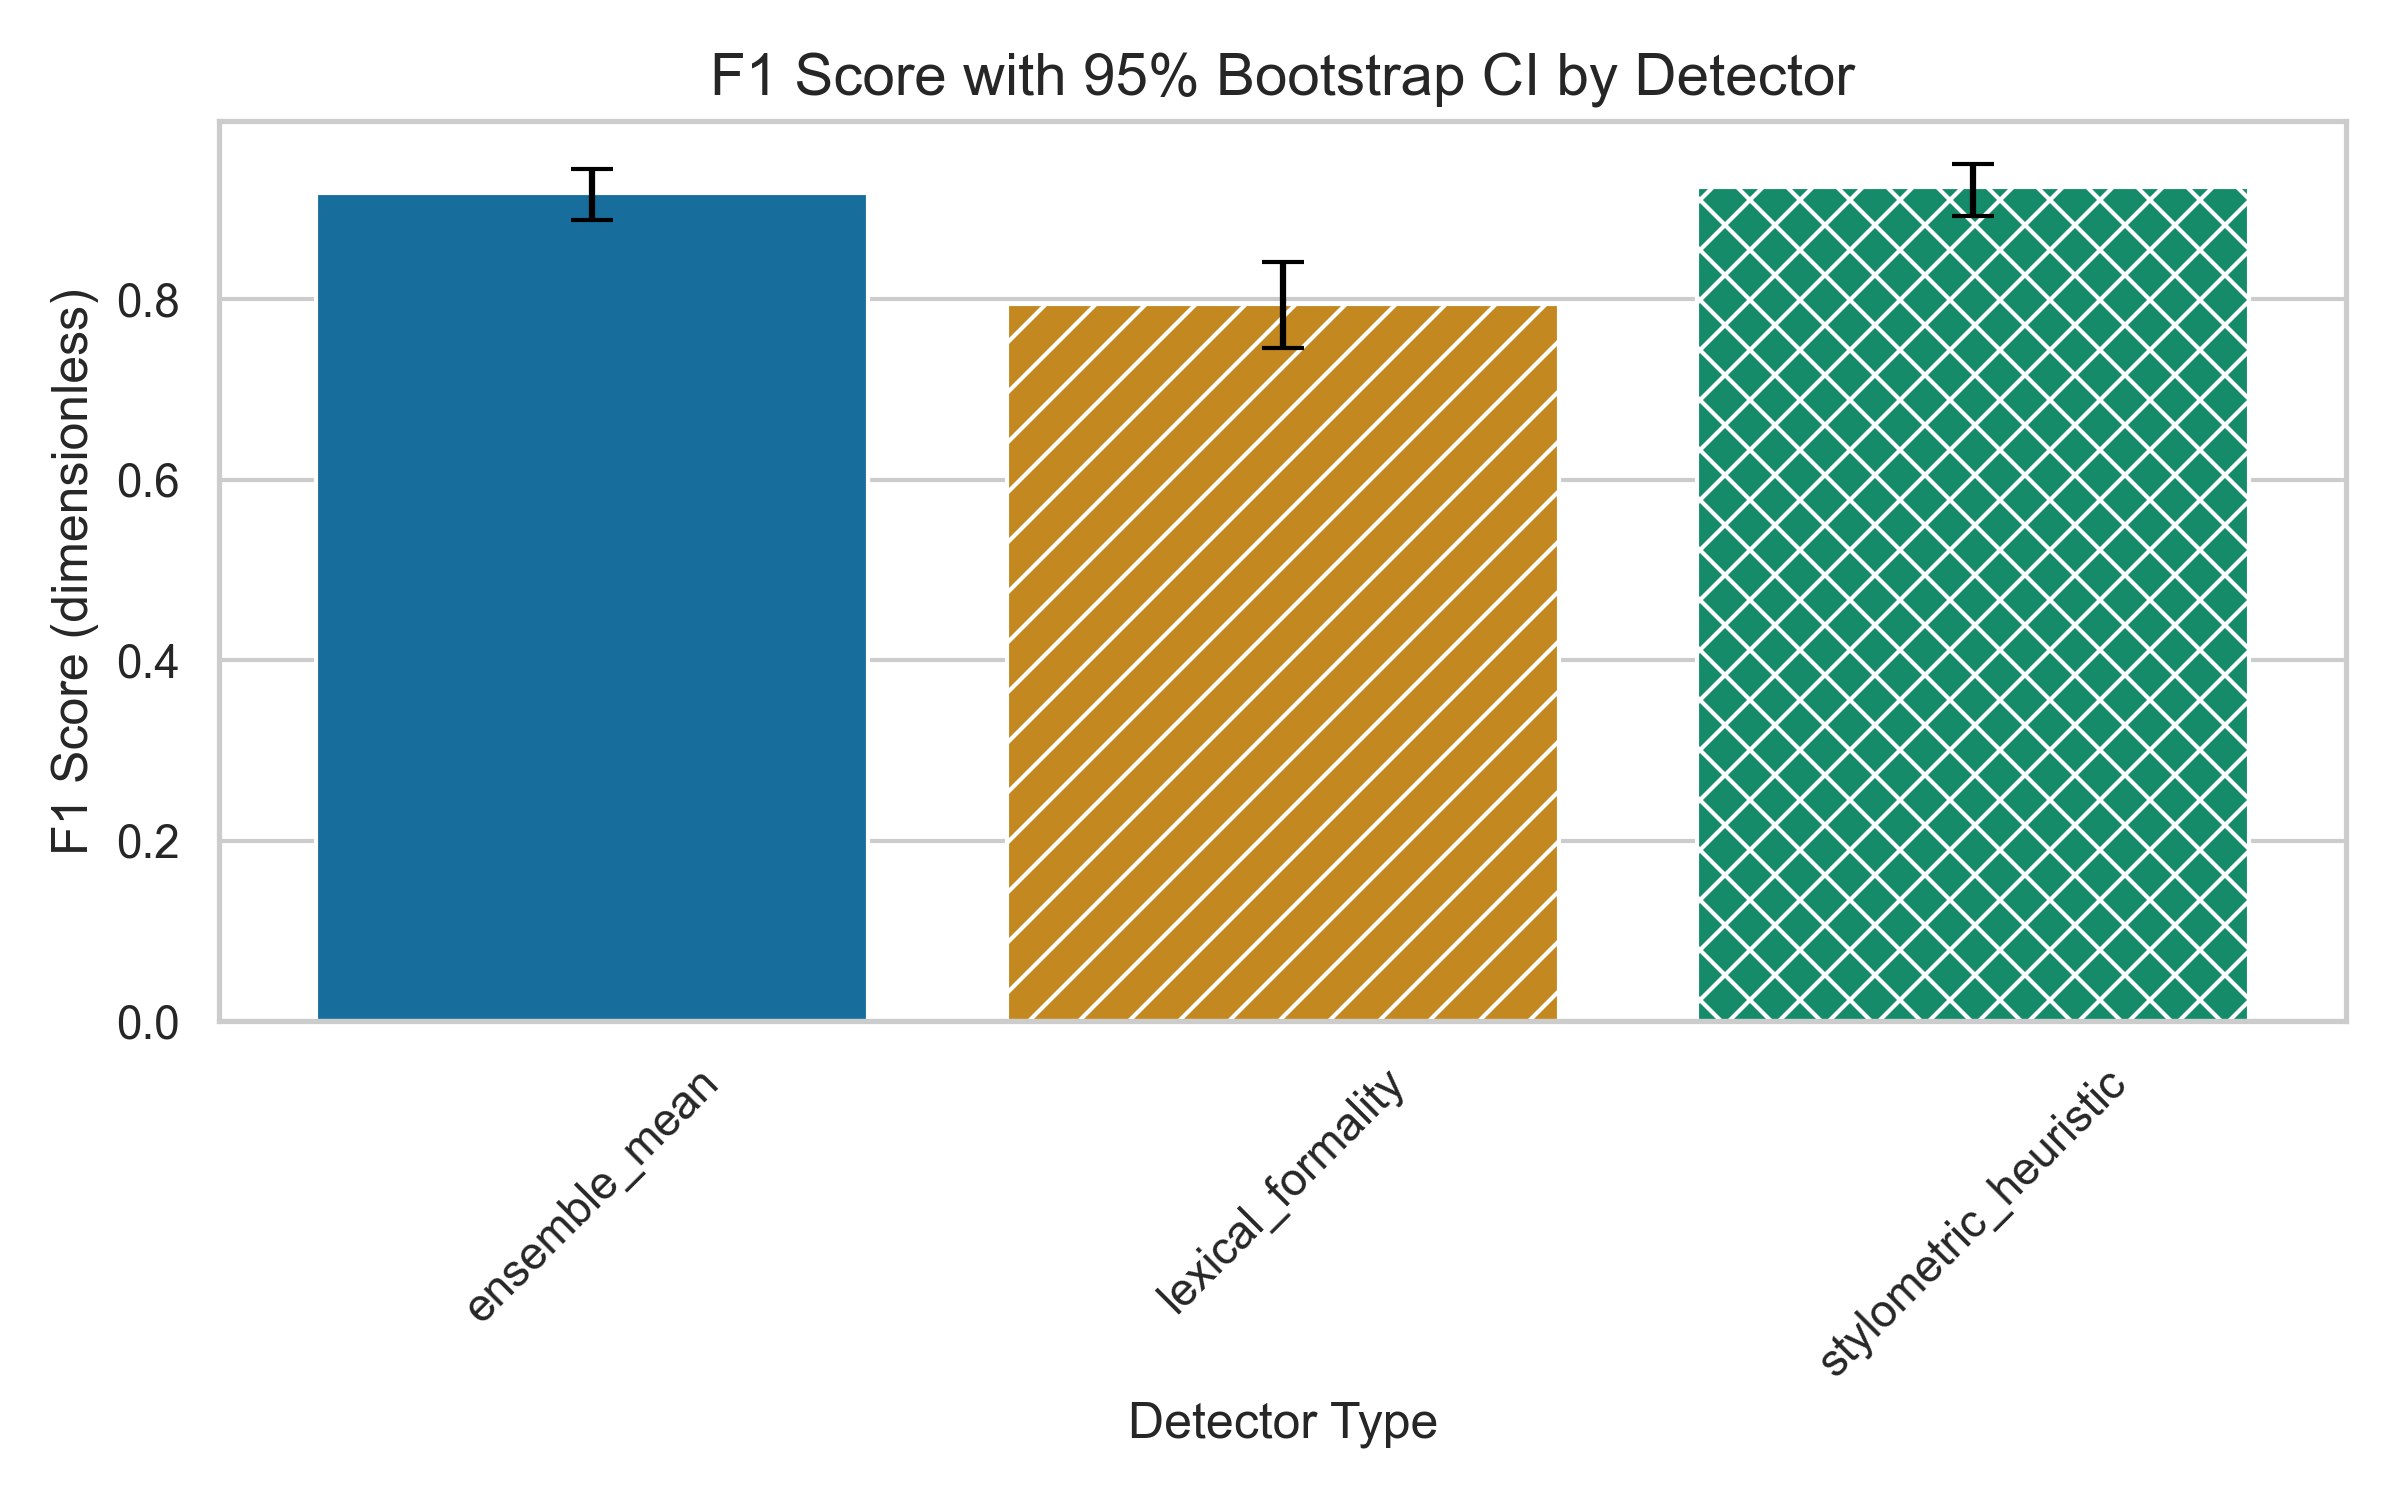

In [5]:
from IPython.display import Image

print("Figure 1: Latency vs Load")
display(Image(filename=str(PROJECT_ROOT / "reports/figures/fig1_latency_vs_load.png")))
print("Figure 2: F1 Distribution")
display(Image(filename=str(PROJECT_ROOT / "reports/figures/fig2_distribution_boxplot.png")))
